In [1]:
import pandas as pd
import matplotlib.pyplot as plt

e = pd.read_csv("data/clean/ecarts_mensuel_vs_journalier.csv", encoding="utf-8-sig")
cols = [c for c in e.columns if c.endswith("_ecart_%")]
pire = e.set_index("mois")[cols].abs().max(axis=1)      # plus grand ecart du mois, tous groupes

m = pd.read_csv("data/clean/ventes_mensuel.csv", encoding="utf-8-sig")
pire = pire.reindex(m["date_fin_mois"].str[:7], fill_value=0)   # les 70 mois, 0 si aucun ecart
n = int((pire > 0).sum())
print(n, "mois en ecart sur", len(pire))
display(pire.sort_values(ascending=False).head(4))


31 mois en ecart sur 70


date_fin_mois
2014-10    74.9
2014-01    66.7
2018-04    46.7
2019-09    32.6
dtype: float64

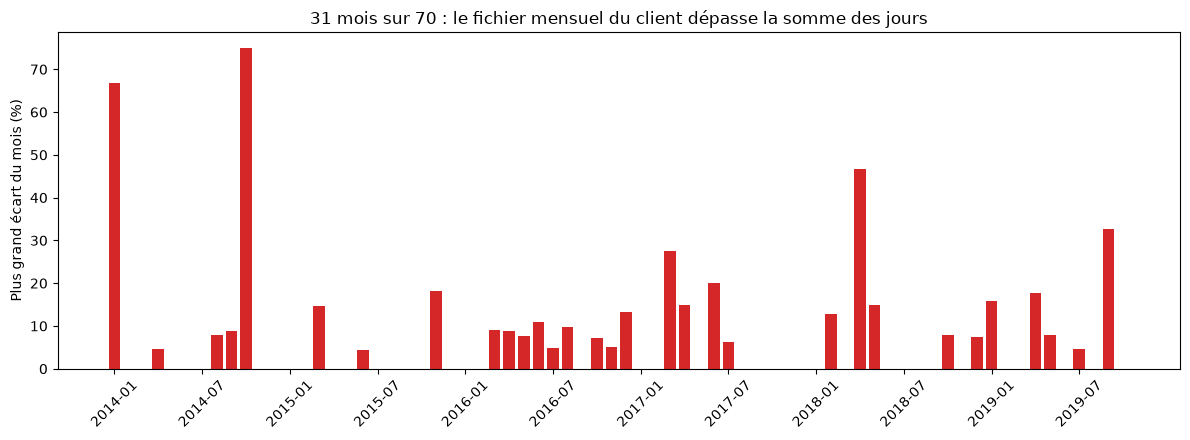

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(range(len(pire)), pire.values, color="tab:red")
ax.set_xticks(range(0, len(pire), 6))
ax.set_xticklabels(pire.index[::6], rotation=45)
ax.set_ylabel("Plus grand écart du mois (%)")
ax.set_title(f"{n} mois sur {len(pire)} : le fichier mensuel du client dépasse la somme des jours")
plt.tight_layout()
plt.savefig("graphique_controle_mensuel.png", dpi=150)
plt.show()
